## Gradient Descent and Logistic Regression

### Question 1:  Linear Regression using Gradient Descent

Tasks:
- Create a CSV file.
- Find the fitted linear regression using gradient descent.
- Compare coefficients with sklearn.
- Compute MSE and RMSE.
- The lab asks for log loss; binary log loss is not applicable because daughter height is continuous.
- Plot blue data points and a red best-fit line.
- Predict daughter height for mother height = 63.
- Plot error vs iteration for 4 epochs × 6 samples = 24 iterations.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

In [3]:
data = {
    "mother_height": [58, 62, 60, 64, 67, 70],
    "daughter_height": [60, 60, 58, 60, 70, 72]
}

df = pd.DataFrame(data)
df.to_csv("mother_daughter.csv", index=False)
print(df)

   mother_height  daughter_height
0             58               60
1             62               60
2             60               58
3             64               60
4             67               70
5             70               72


In [4]:
df = pd.read_csv("mother_daughter.csv")
X = df["mother_height"].values
y = df["daughter_height"].values
n = len(X)

In [5]:
w = 0.0
b = 0.0
alpha = 0.0001
epochs = 4

errors = []
iteration = 0

for epoch in range(epochs):
    for i in range(n):
        x_i = X[i]
        y_i = y[i]

        y_pred = w * x_i + b

        # Squared loss for this iteration
        error = 0.5 * (y_pred - y_i) ** 2
        errors.append(error)

        dw = (y_pred - y_i) * x_i
        db = y_pred - y_i

        w = w - alpha * dw
        b = b - alpha * db

        iteration += 1

        print("Iteration:", iteration,
              "w:", w,
              "b:", b,
              "Error:", error)

Iteration: 1 w: 0.34800000000000003 b: 0.006 Error: 1800.0
Iteration: 2 w: 0.5861916 b: 0.009841800000000001 Error: 737.971362
Iteration: 3 w: 0.7231035732000001 b: 0.01212366622 Error: 260.34567229885437
Iteration: 4 w: 0.8108427581534721 b: 0.013494590984898 Error: 93.97173555053178
Iteration: 5 w: 0.9157650302587796 b: 0.015060595046171249 Error: 122.61843599621523
Iteration: 6 w: 0.9709347412666545 b: 0.015848733774855173 Error: 31.05813278257573
Iteration: 7 w: 0.9922203716486577 b: 0.01621572740213109 Error: 6.7342161230567985
Iteration: 8 w: 0.9827103232770205 b: 0.0160623395251692 Error: 1.1763920399438195
Iteration: 9 w: 0.976838232860142 b: 0.01596447135155456 Error: 0.47890897033326474
Iteration: 10 w: 0.9606231200639779 b: 0.015711110214114497 Error: 3.2095932982461566
Iteration: 11 w: 0.9982941370288236 b: 0.016273364198664434 Error: 15.806477157114069
Iteration: 12 w: 1.0130160963353094 b: 0.016483677903042802 Error: 2.211592712467569
Iteration: 13 w: 1.0201418761962737 b

In [6]:
y_pred_final = w * X + b

mse = np.mean((y - y_pred_final) ** 2)
rmse = np.sqrt(mse)

print("Gradient Descent coefficients:")
print("w =", w)
print("b =", b)

print("\nMSE =", mse)
print("RMSE =", rmse)
print("Log Loss = Not applicable for continuous linear regression")

Gradient Descent coefficients:
w = 1.0149205396744159
b = 0.016406249586034958

MSE = 7.985382074972457
RMSE = 2.8258418347410132
Log Loss = Not applicable for continuous linear regression


In [7]:
model = LinearRegression()
model.fit(X.reshape(-1, 1), y)

print("Our Gradient Descent model:")
print("w =", w)
print("b =", b)

print("\nSklearn model:")
print("w =", model.coef_[0])
print("b =", model.intercept_)

Our Gradient Descent model:
w = 1.0149205396744159
b = 0.016406249586034958

Sklearn model:
w = 1.2060301507537687
b = -13.249581239530976


In [8]:
new_x = 63
prediction = w * new_x + b
print("Predicted daughter height =", prediction)

Predicted daughter height = 63.956400249074235


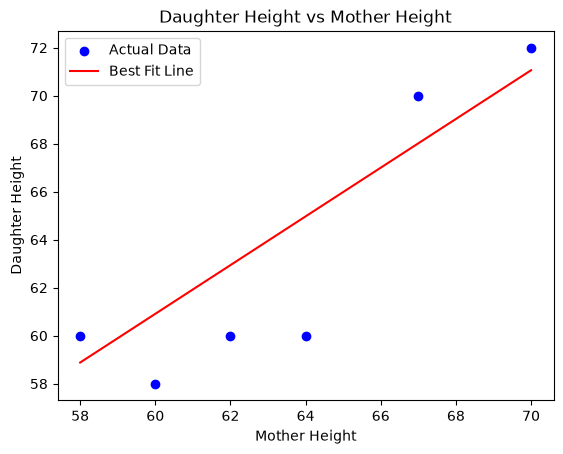

In [9]:
sort_index = np.argsort(X)

plt.scatter(X, y, color="blue", label="Actual Data")
plt.plot(X[sort_index],
         y_pred_final[sort_index],
         color="red",
         label="Best Fit Line")

plt.xlabel("Mother Height")
plt.ylabel("Daughter Height")
plt.title("Daughter Height vs Mother Height")
plt.legend()
plt.show()

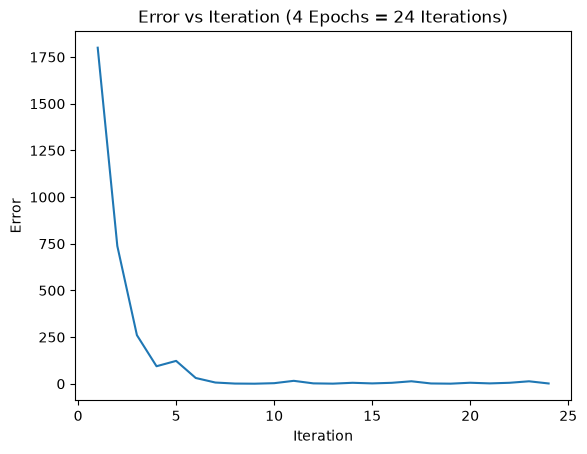

In [10]:
plt.plot(range(1, len(errors) + 1), errors)
plt.xlabel("Iteration")
plt.ylabel("Error")
plt.title("Error vs Iteration (4 Epochs = 24 Iterations)")
plt.show()

### Question 2 — Logistic Regression using Gradient Descent

Tasks:
- Create CSV.
- Perform logistic regression using gradient descent.
- Compare coefficients with sklearn.
- Predict probabilities and assign class labels using 0.5.
- Compute accuracy.
- Find error for each iteration.
- Predict probabilities for 3.5 and 7.5 hours.
- Plot error vs iteration for 3 × 8 = 24 iterations.

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

In [12]:
data = {
    "Hours": [1, 2, 3, 4, 5, 6, 7, 8],
    "Pass": [0, 0, 0, 0, 1, 1, 1, 1]
}

df = pd.DataFrame(data)
df.to_csv("study_pass.csv", index=False)
print(df)

   Hours  Pass
0      1     0
1      2     0
2      3     0
3      4     0
4      5     1
5      6     1
6      7     1
7      8     1


In [13]:
df = pd.read_csv("study_pass.csv")
X = df["Hours"].values
y = df["Pass"].values

def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

In [14]:
w = 0.0
b = 0.0
alpha = 0.01
epochs = 3

errors = []
iteration = 0

for epoch in range(epochs):
    for i in range(len(X)):
        x_i = X[i]
        y_i = y[i]

        p = sigmoid(w * x_i + b)

        # Binary cross-entropy / log loss
        error = -(y_i * np.log(p) + (1 - y_i) * np.log(1 - p))
        errors.append(error)

        dw = (p - y_i) * x_i
        db = p - y_i

        w = w - alpha * dw
        b = b - alpha * db

        iteration += 1

        print("Iteration:", iteration,
              "w:", w,
              "b:", b,
              "Error:", error)

Iteration: 1 w: -0.005 b: -0.005 Error: 0.6931471805599453
Iteration: 2 w: -0.014925001406218361 b: -0.009962500703109181 Error: 0.6856753052962775
Iteration: 3 w: -0.029514572591232774 b: -0.014825691098113984 Error: 0.6661529056578812
Iteration: 4 w: -0.048187684734555467 b: -0.019493969133944657 Error: 0.6289108367916084
Iteration: 5 w: -0.019950555706551205 b: -0.013846543328343806 Error: 0.8318176540921884
Iteration: 6 w: 0.012049720335096086 b: -0.008513163988069257 Error: 0.7621499107257539
Iteration: 7 w: 0.0457232456080546 b: -0.003702660377646612 Error: 0.6559484352879411
Iteration: 8 w: 0.07855967363889327 b: 0.0004018931262082222 Error: 0.5284048203725018
Iteration: 9 w: 0.07336237222468889 b: -0.004795408287996151 Error: 0.7334071276843449
Iteration: 10 w: 0.06265391440557475 b: -0.01014963719755322 Error: 0.7666277301043882
Iteration: 11 w: 0.04632382623102825 b: -0.015592999922402054 Error: 0.7860001811699601
Iteration: 12 w: 0.02463086418203252 b: -0.021016240434650987 

In [15]:
model = LogisticRegression(C=1e6, solver="lbfgs")
model.fit(X.reshape(-1, 1), y)

print("Our model:")
print("w =", w)
print("b =", b)

print("\nSklearn model:")
print("w =", model.coef_[0])
print("b =", model.intercept_)

Our model:
w = 0.15473772325304522
b = -0.01385818786901364

Sklearn model:
w = [18.38171086]
b = [-82.16174593]


In [16]:
probabilities = sigmoid(w * X + b)
predicted_labels = np.where(probabilities >= 0.5, 1, 0)

print("Probabilities:", probabilities)
print("Predicted Labels:", predicted_labels)

accuracy = np.mean(predicted_labels == y)
print("Accuracy =", accuracy)

Probabilities: [0.53516175 0.57337077 0.61072363 0.64682057 0.68131692 0.71393404
 0.74446489 0.77277436]
Predicted Labels: [1 1 1 1 1 1 1 1]
Accuracy = 0.5


In [17]:
for hours in [3.5, 7.5]:
    probability = sigmoid(w * hours + b)
    prediction = 1 if probability >= 0.5 else 0

    print("\nHours:", hours)
    print("Probability of passing:", probability)
    print("Prediction:", prediction)


Hours: 3.5
Probability of passing: 0.6289520783255634
Prediction: 1

Hours: 7.5
Probability of passing: 0.7589030199759883
Prediction: 1


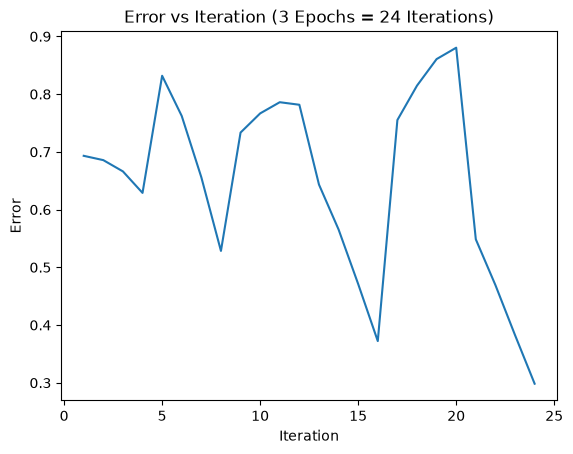

In [18]:
plt.plot(range(1, len(errors) + 1), errors)
plt.xlabel("Iteration")
plt.ylabel("Error")
plt.title("Error vs Iteration (3 Epochs = 24 Iterations)")
plt.show()

### Question 3 — Logistic Regression with Two Independent Variables

The supplied Y values are [2, -14, 1, -1, -7, -8], which are not binary.

For this logistic-regression demonstration, the explicit assumption is:

- Y > 0 → class 1
- Y ≤ 0 → class 0

Therefore the binary target is [1, 0, 1, 0, 0, 0].

In [19]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

data = {
    "X1": [4, 2, 1, 3, 1, 6],
    "X2": [1, 8, 0, 2, 4, 7],
    "Y": [2, -14, 1, -1, -7, -8]
}

df = pd.DataFrame(data)
print(df)

   X1  X2   Y
0   4   1   2
1   2   8 -14
2   1   0   1
3   3   2  -1
4   1   4  -7
5   6   7  -8


In [20]:
X = df[["X1", "X2"]].values
y = np.where(df["Y"] > 0, 1, 0)

print("Binary target:", y)

Binary target: [1 0 1 0 0 0]


In [21]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

w = np.zeros(2)
b = 0.0

learning_rate = 0.01
epochs = 1000
n = len(X)

for epoch in range(epochs):
    z = np.dot(X, w) + b
    probabilities = sigmoid(z)

    error = probabilities - y

    dw = np.dot(X.T, error) / n
    db = np.mean(error)

    w = w - learning_rate * dw
    b = b - learning_rate * db

print("Our Logistic Regression Model:")
print("w1 =", w[0])
print("w2 =", w[1])
print("b =", b)

Our Logistic Regression Model:
w1 = 0.6064264963109738
w2 = -1.4956509693830586
b = 0.3892026246576095


In [22]:
probabilities = sigmoid(np.dot(X, w) + b)
predicted_labels = np.where(probabilities >= 0.5, 1, 0)

print("Probabilities:", probabilities)
print("Predicted Labels:", predicted_labels)
print("Actual Labels:", y)

accuracy = np.mean(predicted_labels == y)
print("Accuracy =", accuracy)

Probabilities: [7.89058171e-01 3.15737742e-05 7.30198344e-01 3.13712468e-01
 6.78000223e-03 1.59100807e-03]
Predicted Labels: [1 0 1 0 0 0]
Actual Labels: [1 0 1 0 0 0]
Accuracy = 1.0


In [23]:
model = LogisticRegression(C=1e6, solver="lbfgs")
model.fit(X, y)

print("Our model:")
print("w1 =", w[0])
print("w2 =", w[1])
print("b =", b)

print("\nSklearn model:")
print("w1 =", model.coef_[0][0])
print("w2 =", model.coef_[0][1])
print("b =", model.intercept_[0])

Our model:
w1 = 0.6064264963109738
w2 = -1.4956509693830586
b = 0.3892026246576095

Sklearn model:
w1 = 4.166885141787414
w2 = -12.248408636575926
b = 4.150323259794476
